# Crop a video
This notebook let you crop a video, allowing to specify the top-left and bottom-right coordinates of the crop rectangle. This reduces the amount of data that the next algorithms need to process.

Workflow: load the first frame, view it with a pixel grid, choose crop coordinates, preview the crop, then apply it to the whole video.

In [ ]:
# This notebook uses OpenCV and Matplotlib. Install them, if you haven't already, by running the following command:

#%pip install opencv-python matplotlib

## Step 1: Load the video and its first frame
Sets the input path (`VIDEO`), reads the first frame, and prints the frame width, height, frame rate and frame count.

In [ ]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

VIDEO = Path("/your/path/to/the/video/file.mp4")

cap = cv2.VideoCapture(str(VIDEO))
ok, frame = cap.read()  # first frame (BGR)
fps = cap.get(cv2.CAP_PROP_FPS)
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()
assert ok, f"Could not read {VIDEO}"

H, W = frame.shape[:2]
print(f"Width={W}, Height={H}, FPS={fps:.2f}, Frames={n_frames}")

Width=1920, Height=1080, FPS=59.94, Frames=222


## Step 2: Show the first frame with a pixel grid
Defines `show_frame()`, which plots a frame with labelled x/y pixel coordinates and a yellow grid (default spacing 100 px; use a smaller `grid` for finer reading). It can also overlay a crop rectangle. The call below displays the first frame so you can read off the crop coordinates.

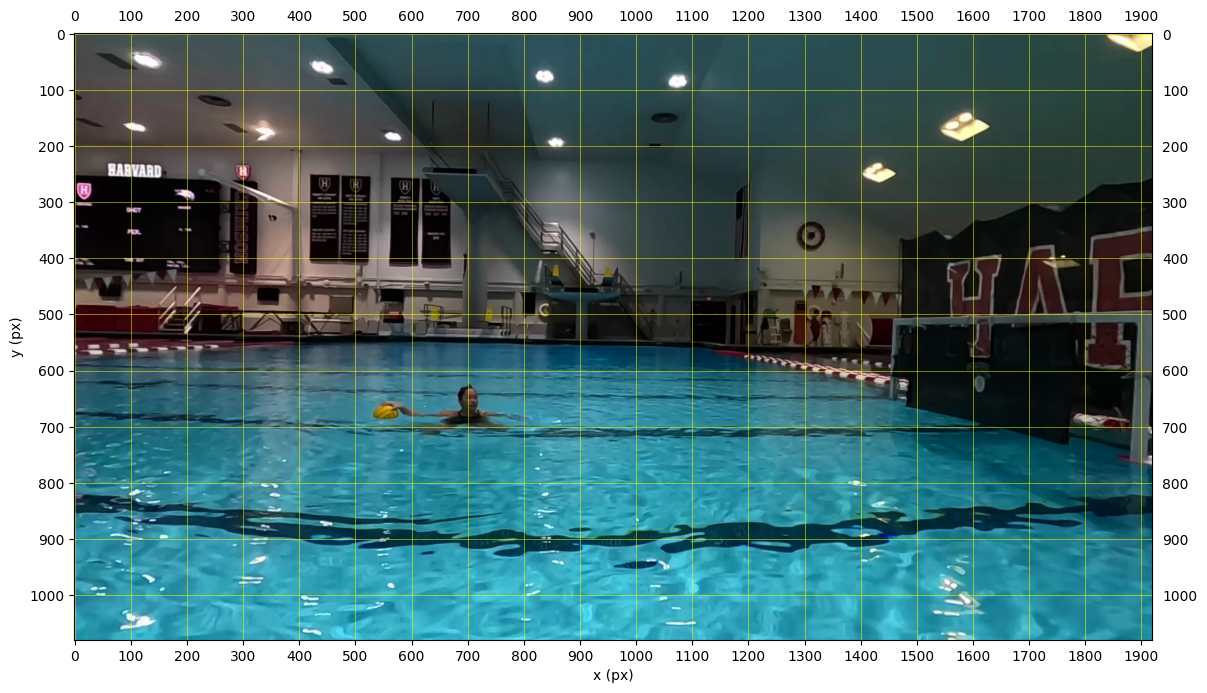

In [3]:
def show_frame(img, crop=None, grid=100):
    """Show frame with pixel-coordinate grid; optionally overlay crop = (x_min, y_min, x_max, y_max)."""
    fig, ax = plt.subplots(figsize=(14, 14 * img.shape[0] / img.shape[1]))
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_xticks(range(0, img.shape[1] + 1, grid))
    ax.set_yticks(range(0, img.shape[0] + 1, grid))
    ax.tick_params(labeltop=True, labelright=True)
    ax.grid(True, color="yellow", alpha=0.5, linewidth=0.7)
    if crop:
        x0, y0, x1, y1 = crop
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", linewidth=2))
    ax.set_xlabel("x (px)"); ax.set_ylabel("y (px)")
    plt.show()

show_frame(frame, grid=100)  # use grid=50 or 25 for finer reading

## Step 3: Choose and preview the crop
Set `top_left` and `bottom_right` as `(x, y)` pixel coordinates read from the grid (x increases to the right, y increases downward, origin at the top-left of the frame). The other two corners follow automatically. The cell checks the crop is within the frame, makes the width and height even (required by the H.264 encoder), then shows the crop box (red) on the full frame and the cropped result. Re-run it with new values until you are happy.

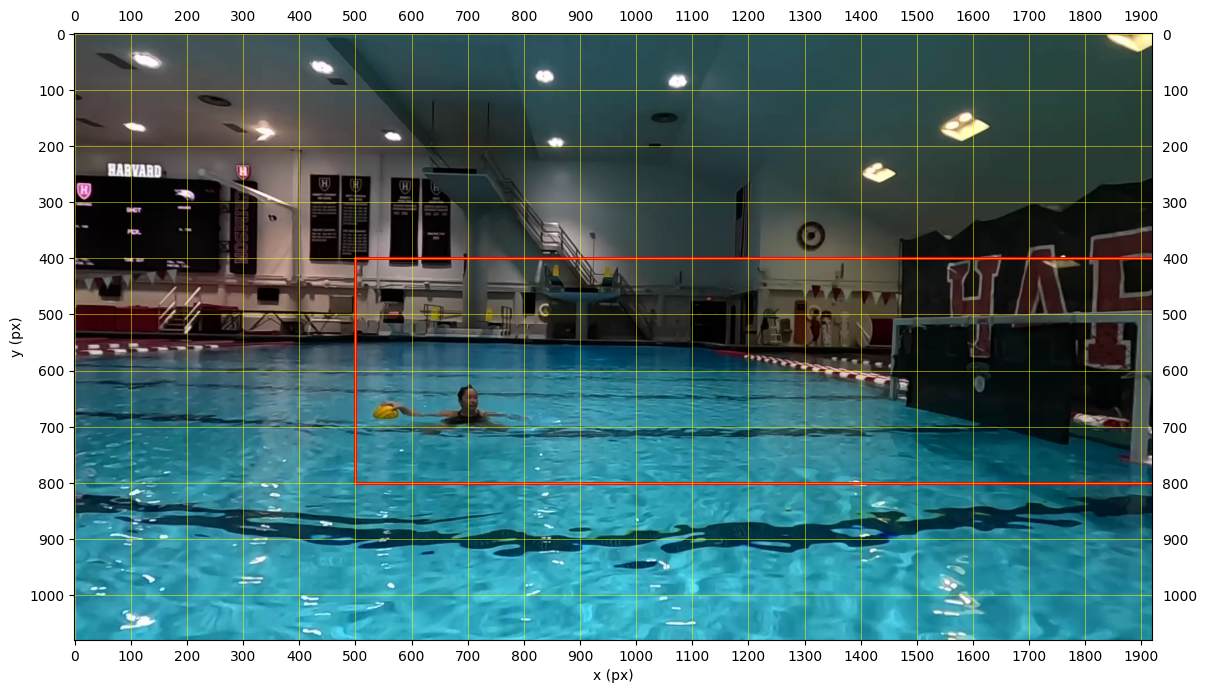

Crop (500, 400, 1920, 800) -> 1420 x 400


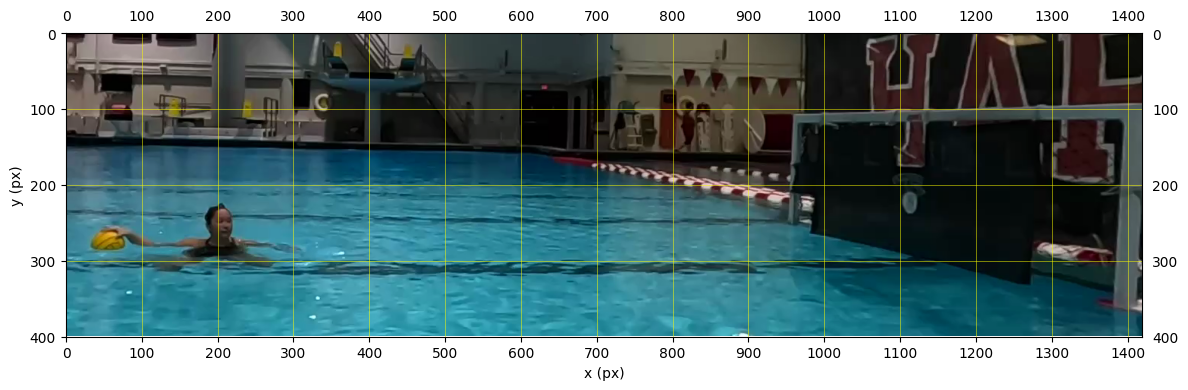

In [6]:
# Edit these from the grid, then re-run this cell to preview. (x right, y down; origin = top-left of frame)
top_left     = (500, 400) #(x, y) of top-left corner of crop rectangle
bottom_right = (1920, 800) #(x, y) of bottom-right corner of crop rectangle
#bottom_right = (W, H)
# top_right = (bottom_right[0], top_left[1]); bottom_left = (top_left[0], bottom_right[1]) follow automatically.

x_min, y_min = top_left
x_max, y_max = bottom_right
assert 0 <= x_min < x_max <= W and 0 <= y_min < y_max <= H, "Crop out of bounds"
# libx264/yuv420p needs even dimensions
x_max -= (x_max - x_min) % 2
y_max -= (y_max - y_min) % 2
CROP = (x_min, y_min, x_max, y_max)

show_frame(frame, crop=CROP)
cropped = frame[y_min:y_max, x_min:x_max]
print(f"Crop {CROP} -> {x_max - x_min} x {y_max - y_min}")
show_frame(cropped, grid=100)

## Step 4: Trim the whole video
Once the preview looks right, run the cell below. It applies the crop to every frame of the video using ffmpeg (or OpenCV if ffmpeg is not installed; OpenCV drops audio). The result is saved in the same folder as the input, named `<input_name>_trimmed.<extension>`.

In [ ]:
import subprocess, shutil

OUT = VIDEO.with_name(f"{VIDEO.stem}_trimmed{VIDEO.suffix}")
w, h = x_max - x_min, y_max - y_min

if shutil.which("ffmpeg"):
    subprocess.run(
        ["ffmpeg", "-y", "-loglevel", "error", "-i", str(VIDEO), "-vf", f"crop={w}:{h}:{x_min}:{y_min}",
         "-c:v", "libx264", "-crf", "18", "-pix_fmt", "yuv420p", "-c:a", "copy", str(OUT)],
        check=True,
    )
else:  # fallback: OpenCV (drops audio)
    cap = cv2.VideoCapture(str(VIDEO))
    writer = cv2.VideoWriter(str(OUT), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
    while True:
        ok, f = cap.read()
        if not ok:
            break
        writer.write(f[y_min:y_max, x_min:x_max])
    cap.release(); writer.release()

print(f'Trimmed video saved as "{OUT.name}" in {OUT.parent}')